In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/janadarwish/engineered/sprints_cohort_engineered.csv


# 03 — Data Visualization and Dashboard

## Objective
Visualize learner performance, engagement, and skill mastery to identify useful insights for talent pipeline optimization.

## Key Questions
- How do average scores vary across modules?
- How are learners distributed across performance categories?
- Is engagement associated with skill mastery?
- How does learner performance vary across training tracks?

## Tools
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/janadarwish/engineered/sprints_cohort_engineered.csv


In [6]:
import os

print("Working directory files:")
print(os.listdir("/kaggle/working"))

Working directory files:
['sprints_pygwalker_config.json', '.virtual_documents']


In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
file_path = "/kaggle/input/datasets/janadarwish/engineered/sprints_cohort_engineered.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (24, 21)


,learner_id,cohort_id,enrollment_date,graduation_date,demographic_group,track_name,engagement_score,module_1_score,module_2_score,module_3_score,...,module_5_score,module_6_score,module_7_score,module_8_score,module_9_score,module_10_score,capstone_score,Skill_Mastery_Index,Performance_Category,Performance_Gap
0,LRN-1001,2023-Q1-DA,2023-01-15,2023-07-20,Group_A,Advanced Data Analysis,85.0,90,88.0,92.0,...,89.0,94.0,88.0,91.0,95.0,90.0,93.0,90.200000,High,-2.800000
1,LRN-1002,2023-Q1-DA,2023-01-15,2023-07-20,Group_B,Advanced Data Analysis,NaN,70,75.0,NaN,...,80.0,77.0,81.0,72.0,68.0,74.0,76.0,73.555556,Medium,-2.444444
2,LRN-1003,2023-Q2-AI,2023-04-10,2023-10-15,Group_A,AI & Machine Learning,92.0,95,96.0,91.0,...,94.0,99.0,90.0,92.0,95.0,97.0,96.0,94.700000,High,-1.300000
3,LRN-1004,2023-Q1-FS,2023-01-15,2023-07-20,Group_C,Full Stack Web Development,45.0,60,55.0,58.0,...,59.0,61.0,65.0,54.0,55.0,60.0,58.0,58.900000,Low,0.900000
4,LRN-1005,2023-Q2-DA,2023-04-10,2023-10-15,Group_D,Advanced Data Analysis,78.0,80,82.0,79.0,...,81.0,NaN,86.0,88.0,82.0,84.0,85.0,83.000000,Medium,-2.000000


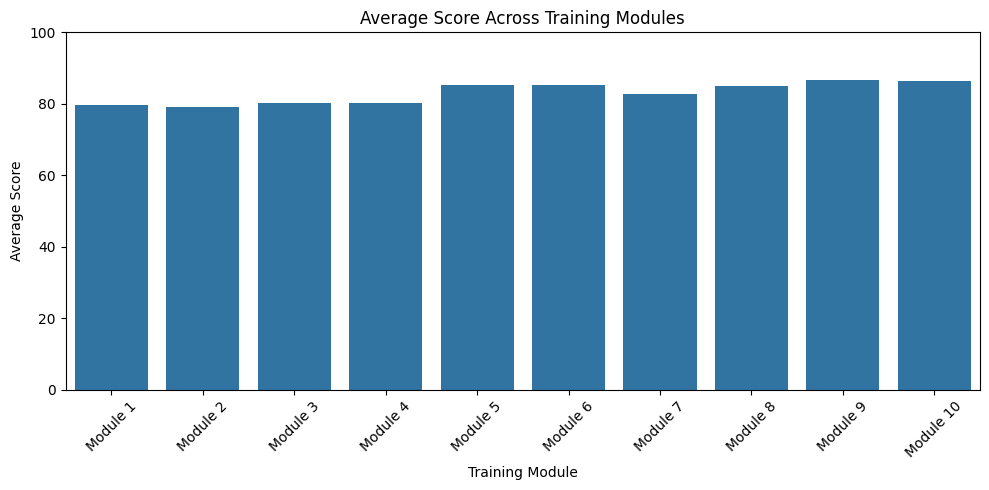

In [9]:
score_columns = [
    f"module_{i}_score" for i in range(1, 11)
]

module_averages = df[score_columns].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=[f"Module {i}" for i in range(1, 11)],
    y=module_averages.values
)

plt.title("Average Score Across Training Modules")
plt.xlabel("Training Module")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

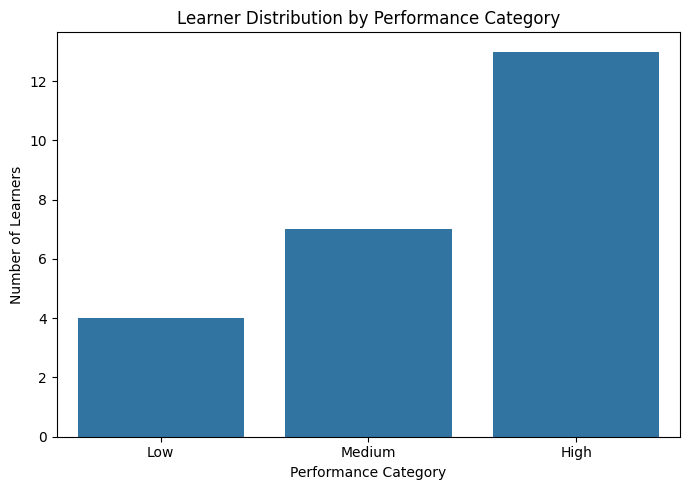

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Performance_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Learner Distribution by Performance Category")
plt.xlabel("Performance Category")
plt.ylabel("Number of Learners")
plt.tight_layout()
plt.show()

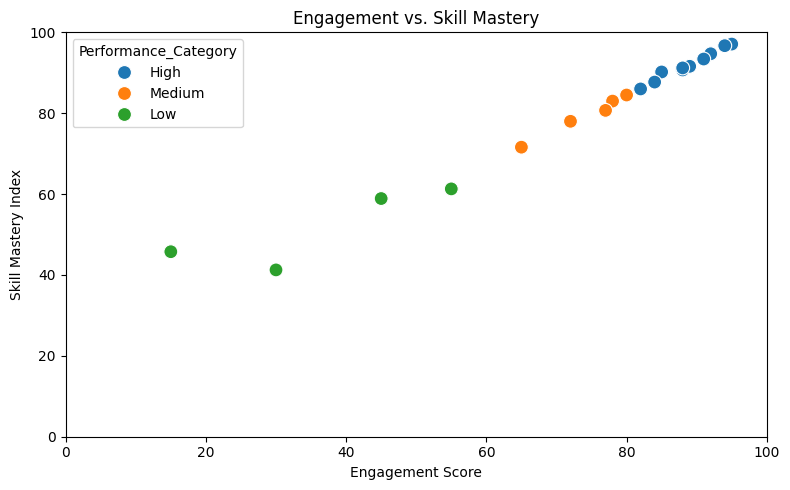

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="engagement_score",
    y="Skill_Mastery_Index",
    hue="Performance_Category",
    s=100
)

plt.title("Engagement vs. Skill Mastery")
plt.xlabel("Engagement Score")
plt.ylabel("Skill Mastery Index")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

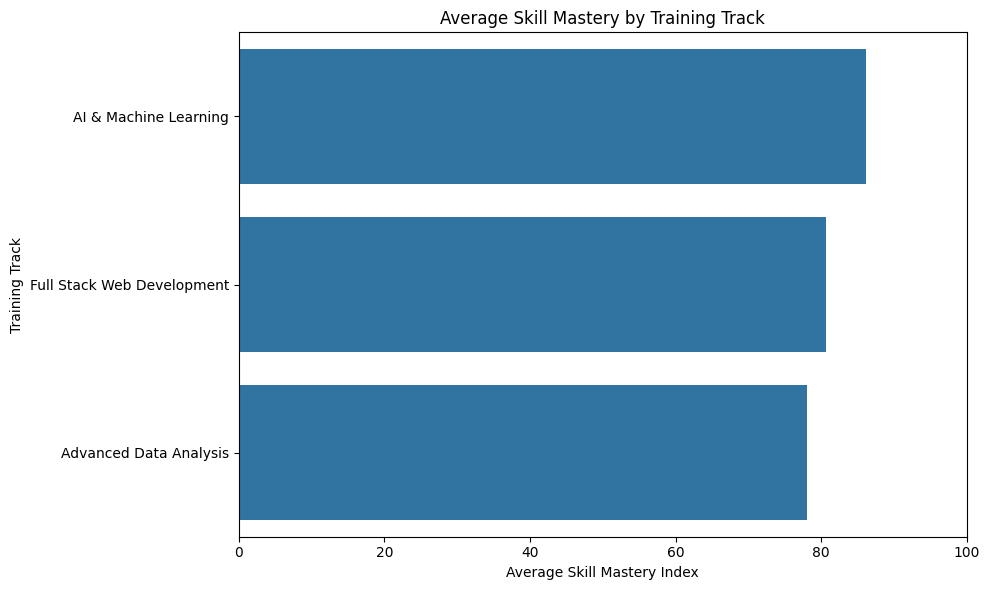

In [12]:
track_performance = (
    df.groupby("track_name")["Skill_Mastery_Index"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=track_performance.values,
    y=track_performance.index
)

plt.title("Average Skill Mastery by Training Track")
plt.xlabel("Average Skill Mastery Index")
plt.ylabel("Training Track")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## Key Findings and Business Insights

- Average module scores generally increase across the training program, from 79.58 in Module 1 to 86.24 in Module 10.
- Learners are grouped into High, Medium, and Low performance categories using the thresholds defined in Notebook 02.
- The engagement-versus-mastery scatter plot helps explore whether learner engagement is associated with skill mastery. Missing engagement values are excluded from this visualization.
- Comparing skill mastery across training tracks helps identify differences in the current sample. However, the dataset is small, so results should be interpreted cautiously.
- These visualizations can help guide further investigation into learner support and talent pipeline optimization, but they do not establish causation.

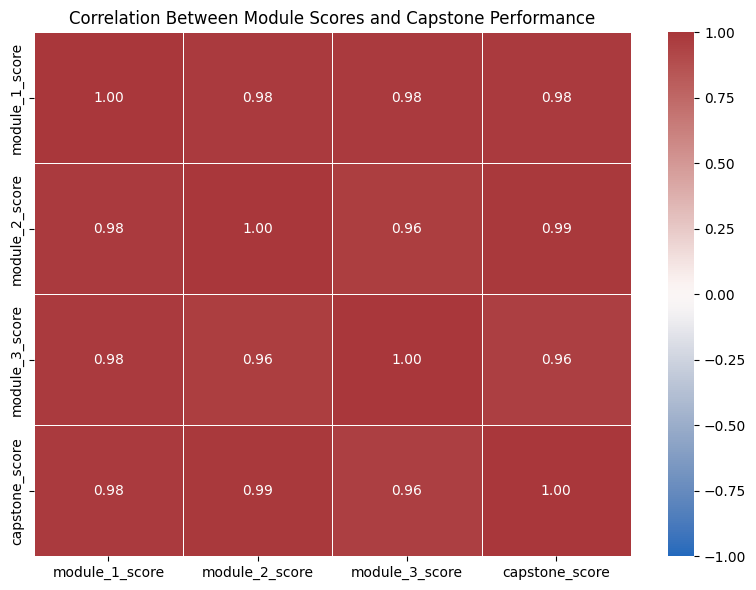

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    "module_1_score",
    "module_2_score",
    "module_3_score",
    "capstone_score"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Module Scores and Capstone Performance")
plt.tight_layout()
plt.show()

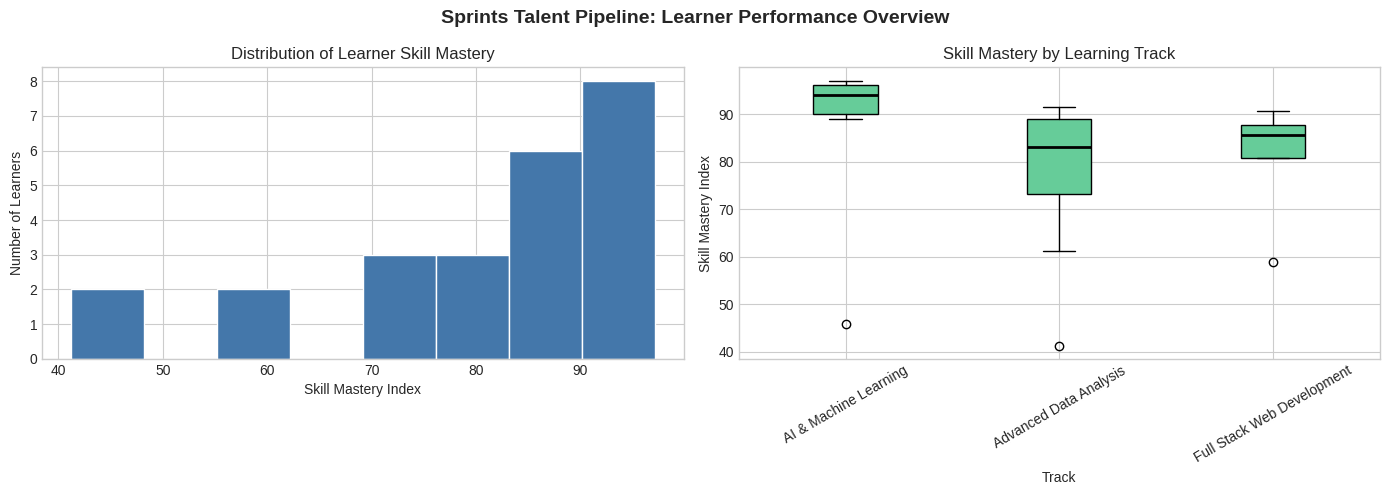

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Colorblind-friendly palette
plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Skill Mastery Index distribution
mastery_scores = df["Skill_Mastery_Index"].dropna()

axes[0].hist(
    mastery_scores,
    bins=8,
    color="#4477AA",
    edgecolor="white"
)

axes[0].set_title("Distribution of Learner Skill Mastery")
axes[0].set_xlabel("Skill Mastery Index")
axes[0].set_ylabel("Number of Learners")

# Chart 2: Skill Mastery Index by Track
track_data = [
    group["Skill_Mastery_Index"].dropna().values
    for _, group in df.groupby("track_name")
]

track_labels = [
    name for name, group in df.groupby("track_name")
    if group["Skill_Mastery_Index"].notna().any()
]

axes[1].boxplot(
    track_data,
    tick_labels=track_labels,
    patch_artist=True,
    boxprops=dict(facecolor="#66CC99"),
    medianprops=dict(color="black", linewidth=2)
)

axes[1].set_title("Skill Mastery by Learning Track")
axes[1].set_xlabel("Track")
axes[1].set_ylabel("Skill Mastery Index")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle(
    "Sprints Talent Pipeline: Learner Performance Overview",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

In [15]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Prepare data
dashboard_df = df.copy()

dashboard_df["enrollment_date"] = pd.to_datetime(
    dashboard_df["enrollment_date"], errors="coerce"
)

dashboard_df["graduation_date"] = pd.to_datetime(
    dashboard_df["graduation_date"], errors="coerce"
)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Learner Performance vs Engagement",
        "Average Skill Mastery by Track"
    ),
    horizontal_spacing=0.12
)

# Chart 1: Performance vs engagement
scatter_df = dashboard_df.dropna(
    subset=["engagement_score", "Skill_Mastery_Index"]
)

for category in ["Low", "Medium", "High"]:
    subset = scatter_df[
        scatter_df["Performance_Category"] == category
    ]

    fig.add_trace(
        go.Scatter(
            x=subset["engagement_score"],
            y=subset["Skill_Mastery_Index"],
            mode="markers",
            name=category,
            text=subset["learner_id"],
            customdata=subset[["track_name", "cohort_id"]],
            hovertemplate=(
                "Learner: %{text}<br>"
                "Engagement: %{x:.1f}<br>"
                "Skill Mastery: %{y:.1f}<br>"
                "Track: %{customdata[0]}<br>"
                "Cohort: %{customdata[1]}"
                "<extra></extra>"
            )
        ),
        row=1,
        col=1
    )

# Chart 2: Average mastery by track
track_summary = (
    dashboard_df.groupby("track_name", as_index=False)
    ["Skill_Mastery_Index"].mean()
    .sort_values("Skill_Mastery_Index", ascending=True)
)

fig.add_trace(
    go.Bar(
        x=track_summary["Skill_Mastery_Index"],
        y=track_summary["track_name"],
        orientation="h",
        name="Average Mastery",
        hovertemplate=(
            "Track: %{y}<br>"
            "Average Mastery: %{x:.2f}"
            "<extra></extra>"
        )
    ),
    row=1,
    col=2
)

fig.update_xaxes(
    title_text="Engagement Score",
    range=[0, 100],
    row=1,
    col=1
)
fig.update_yaxes(
    title_text="Skill Mastery Index",
    range=[0, 100],
    row=1,
    col=1
)
fig.update_xaxes(
    title_text="Average Skill Mastery",
    range=[0, 100],
    row=1,
    col=2
)
fig.update_yaxes(title_text="Track", row=1, col=2)

fig.update_layout(
    title="Sprints Talent Pipeline Interactive Dashboard",
    height=550,
    template="plotly_white",
    hovermode="closest"
)

# Add a range slider to the date axis as required.
# This separate timeline chart uses actual enrollment dates.
timeline_df = dashboard_df.dropna(
    subset=["enrollment_date", "Skill_Mastery_Index"]
).sort_values("enrollment_date")

timeline_fig = px.scatter(
    timeline_df,
    x="enrollment_date",
    y="Skill_Mastery_Index",
    color="track_name",
    hover_name="learner_id",
    hover_data=["engagement_score", "cohort_id"],
    title="Learner Skill Mastery by Enrollment Date"
)

timeline_fig.update_xaxes(
    rangeslider_visible=True,
    title="Enrollment Date"
)
timeline_fig.update_yaxes(
    title="Skill Mastery Index",
    range=[0, 100]
)
timeline_fig.show()

fig.show()

In [16]:
import plotly.express as px
import pandas as pd

animation_df = df.copy()

animation_df["enrollment_date"] = pd.to_datetime(
    animation_df["enrollment_date"],
    errors="coerce"
)

animation_df = animation_df.dropna(
    subset=[
        "enrollment_date",
        "Skill_Mastery_Index",
        "engagement_score",
        "cohort_id"
    ]
).copy()

# Create monthly time periods from actual enrollment dates
animation_df["program_month"] = (
    animation_df["enrollment_date"]
    .dt.to_period("M")
    .astype(str)
)

monthly_summary = (
    animation_df.groupby(
        ["program_month", "cohort_id"], as_index=False
    )
    .agg(
        average_mastery=("Skill_Mastery_Index", "mean"),
        average_engagement=("engagement_score", "mean"),
        learner_count=("learner_id", "nunique")
    )
)

monthly_summary = monthly_summary.sort_values("program_month")

fig = px.scatter(
    monthly_summary,
    x="average_engagement",
    y="average_mastery",
    animation_frame="program_month",
    animation_group="cohort_id",
    size="learner_count",
    color="cohort_id",
    hover_name="cohort_id",
    hover_data={
        "average_engagement": ":.2f",
        "average_mastery": ":.2f",
        "learner_count": True,
        "program_month": True
    },
    range_x=[0, 100],
    range_y=[0, 100],
    title="Cohort Engagement vs Skill Mastery Over Time",
    labels={
        "average_engagement": "Average Engagement Score",
        "average_mastery": "Average Skill Mastery Index",
        "program_month": "Program Month"
    }
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()

In [17]:
# Install PyGWalker if it is not already available
%pip install -q pygwalker

Note: you may need to restart the kernel to use updated packages.


In [18]:
import pygwalker as pyg

pyg.walk(
    df,
    spec="./sprints_pygwalker_config.json",
    use_kernel_calc=True
)

Box(children=(HTML(value='\n<div id="ifr-pyg-00065e336e87f46dFZvNceCt0Srm9bsu" style="height: auto">\n    <hea…

In [20]:
import pandas as pd
import plotly.express as px

matching_path = (
    "/kaggle/input/datasets/janadarwish/learner-matching/learner_job_matching_results.csv"
)

matching_df = pd.read_csv(matching_path)

# Count eligible learners for each role
role_summary = (
    matching_df[matching_df["meets_threshold"]]
    .groupby(["role_id", "job_title"])["learner_id"]
    .nunique()
    .reset_index(name="eligible_learners")
    .sort_values("eligible_learners", ascending=False)
)

fig = px.bar(
    role_summary.head(15),
    x="eligible_learners",
    y="job_title",
    orientation="h",
    title="Top 15 Roles by Number of Eligible Learners",
    labels={
        "eligible_learners": "Number of Eligible Learners",
        "job_title": "Job Role"
    },
    hover_data=["role_id"]
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"},
    template="plotly_white"
)

fig.show()

In [21]:
import pandas as pd
import numpy as np
import json
import plotly.express as px

# Load the engineered learner dataset
df = pd.read_csv(
    "/kaggle/input/datasets/janadarwish/engineered/sprints_cohort_engineered.csv"
)

# Keep one record per learner
df = df.drop_duplicates(subset="learner_id").copy()

# Load employer requirements
requirements_path = (
    "/kaggle/input/datasets/janadarwish/sprints-dataset/employer_partner_requirements.json"
)

with open(requirements_path, "r", encoding="utf-8") as file:
    jobs = pd.DataFrame(json.load(file)["employer_requirements"])

# Calculate weighted mastery if it is not already in the dataset
score_columns = [f"module_{i}_score" for i in range(1, 11)]

if "Weighted_Skill_Mastery_Index" not in df.columns:
    scores = df[score_columns].to_numpy(dtype=float)
    weights = np.array([1, 1, 1, 1, 1.1, 1.1, 1.2, 1.2, 1.3, 1.3])
    valid = ~np.isnan(scores)

    numerator = np.nansum(scores * weights, axis=1)
    denominator = np.sum(valid * weights, axis=1)

    df["Weighted_Skill_Mastery_Index"] = np.divide(
        numerator,
        denominator,
        out=np.full(len(df), np.nan),
        where=denominator != 0
    )

# Calculate learner-role eligibility
learner_scores = df["Weighted_Skill_Mastery_Index"].to_numpy(dtype=float)
thresholds = jobs["minimum_assessment_threshold"].to_numpy(dtype=float)
priorities = jobs["priority_weight"].to_numpy(dtype=float)

eligible = learner_scores[:, None] >= thresholds[None, :]
match_scores = np.clip(
    learner_scores[:, None] / thresholds[None, :] * 100,
    0,
    100
)

matching_df = pd.DataFrame({
    "learner_id": np.repeat(df["learner_id"].to_numpy(), len(jobs)),
    "role_id": np.tile(jobs["role_id"].to_numpy(), len(df)),
    "job_title": np.tile(jobs["job_title"].to_numpy(), len(df)),
    "meets_threshold": eligible.ravel(),
    "priority_score": (match_scores * priorities[None, :]).ravel()
})

# Count eligible learners per role
role_summary = (
    matching_df[matching_df["meets_threshold"]]
    .groupby(["role_id", "job_title"])["learner_id"]
    .nunique()
    .reset_index(name="eligible_learners")
    .sort_values("eligible_learners", ascending=False)
)

fig = px.bar(
    role_summary.head(15),
    x="eligible_learners",
    y="job_title",
    orientation="h",
    title="Top 15 Roles by Number of Eligible Learners",
    labels={
        "eligible_learners": "Eligible Learners",
        "job_title": "Job Role"
    },
    hover_data=["role_id"]
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"},
    template="plotly_white"
)

fig.show()

In [22]:
# Get the top 3 eligible roles for each learner
top_matches = (
    matching_df[matching_df["meets_threshold"]]
    .sort_values(
        ["learner_id", "priority_score"],
        ascending=[True, False]
    )
    .groupby("learner_id")
    .head(3)
    .reset_index(drop=True)
)

# Display selected columns
display(
    top_matches[
        [
            "learner_id",
            "role_id",
            "job_title",
            "priority_score"
        ]
    ]
)

,learner_id,role_id,job_title,priority_score
0,LRN-1001,REQ-1009,Data Engineer I,95.0
1,LRN-1001,REQ-1036,Cybersecurity Data Analyst,92.0
2,LRN-1001,REQ-1001,Junior Data Analyst,90.0
3,LRN-1002,REQ-1011,Customer Insights Analyst,50.0
4,LRN-1002,REQ-1037,Market Research Analyst,50.0
5,LRN-1002,REQ-1016,Junior Python Developer (Data),45.0
6,LRN-1003,REQ-1010,Junior Quantitative Analyst,98.0
7,LRN-1003,REQ-1045,Recommendation Systems Engineer,96.0
8,LRN-1003,REQ-1002,Data Scientist I,95.0
9,LRN-1005,REQ-1008,Healthcare Data Analyst,80.0
